# PA2 Task 3 - Group Relative Policy Optimization (Kaggle, also runs on Colab)

**The setup.** GRPO deletes PPO's critic. For each prompt it samples K = 4 answers, scores them with
the reward model, and judges each answer against its siblings: A_k = (r_k - mean) / (std + eps).
Every token of an answer gets that one advantage. All runs start from the **supplied GRPO midpoint**.

| Run | Updates | Normalisation | What it is for |
|---|---|---|---|
| `midpoint` | 0 | - | evaluation only: the starting point |
| `standard` | 20 | canonical (divide by T_k) | required continuation (Task 4 reuses this adapter) |
| `fork_grpo` / `fork_dr_grpo` | 8 each | T_k / constant 512 | normalisation study (matched forks) |
| group-size study | 0 | - | the supplied K=8 cache regrouped into K = 2, 4, 8 (CPU only) |
| `smoke` | 2 | canonical | pipeline test only, **never reported** |

**Four rules this notebook enforces**
1. **The bug fix is proven before any training.** T5 uses a TWO-group batch (the bug is invisible with one group) and the worked examples, and stops on any mismatch.
2. **Forks are matched**: same midpoint, prompt schedule, sampling seed and update budget; at update 1 they must sample *identical* completions, which T11 checks.
3. **One held-out protocol** for every condition (same prompts, decoding, seed, 768-token cap - the same cap as Task 2).
4. **Task 4 uses `standard` only.**

**Inputs (Kaggle):** GPU T4 x2, Internet ON, **dataset `pa2-task3`** (upload `pa2-task3.zip`).
*(Resuming: also attach this notebook's previous output.)*

**Timing on a T4 (rough; T7 prints a real estimate):** about 45 s per update (4 rollouts + 8 scoring
passes + 4 backward passes), so standard 15 min and the two forks 12 min; 4 held-out evaluations at
about 9 min each; the group-size study takes seconds. About 1.5 h in total.

**How to read the output.** `PASS / FAIL / OBSERVE`, then the **expected** and **actual** lines.

## Part A - setup

In [1]:
# T1. Assemble the repo, connect the saved output folder, and layer in the fixed Task 3 files.
import os, sys, glob, json, math, shutil, subprocess, time, zipfile
from pathlib import Path

ON_KAGGLE = os.path.exists('/kaggle/working')
REPO_URL  = 'https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git'
REPO      = '/tmp/PA2'
N_EVAL    = 100
SMOKE_UPD = 2
RUN_PARTS = {'C_standard': True, 'D_group': True, 'E_norm': True}

if ON_KAGGLE:
    OUT, BASE = '/kaggle/working/outputs', '/kaggle/input'
    os.environ['HF_HOME'] = '/tmp/hf'
else:
    from google.colab import drive; drive.mount('/content/drive')
    OUT  = '/content/drive/MyDrive/ATML_PA2/task3_outputs'
    BASE = '/content/drive/MyDrive/ATML_PA2/inputs'
    os.environ['HF_HOME'] = '/content/hf'
for sub in ['outputs', 'results']:
    os.makedirs(f'{OUT}/{sub}', exist_ok=True)

CHECKS = []
def expect(name, expected, actual, ok):
    ok = None if ok is None else bool(ok)      # accept tensor(True) / numpy bools
    tag = {True: 'PASS   ', False: 'FAIL   ', None: 'OBSERVE'}[ok]
    print(f'[{tag}] {name}\n            expected: {expected}\n            actual  : {actual}')
    CHECKS.append((tag.strip(), name))

def run(cmd):
    print('$', cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        if 'Converting a tensor with requires_grad' in line or 'Consider using tensor.detach' in line: continue
        print(line, end='')
    if p.wait() != 0:
        raise RuntimeError(f'Command failed (exit code {p.returncode}): {cmd}')

if not os.path.isdir(f'{REPO}/.git'):
    subprocess.run(f'git clone -q {REPO_URL} {REPO}', shell=True, check=True)
os.chdir(REPO); sys.path.insert(0, REPO)
print('  cloned      :', REPO_URL)

FILES = ['grpo.py', 'continue_train.py', 'evaluate.py', 'analyze_group_size.py', 'compare_normalization.py']
FIX_MARK = 'adv[m] = (r - mu) / (sigma + eps)'
hits = [p for p in glob.glob(f'{BASE}/**/grpo.py', recursive=True) if FIX_MARK in open(p).read()]
if hits:
    src_dir = os.path.dirname(hits[0])
    for f in FILES:
        shutil.copy(f'{src_dir}/{f}', f'{REPO}/task3_grpo/{f}')
    print('  layered in  :', src_dir)
else:
    print('  layered in  : nothing found under', BASE)

for sub in ['outputs', 'results']:
    local = Path(REPO, sub)
    if local.is_symlink():
        continue
    if local.exists():
        shutil.copytree(local, f'{OUT}/{sub}', dirs_exist_ok=True); shutil.rmtree(local)
    local.symlink_to(f'{OUT}/{sub}', target_is_directory=True)
if ON_KAGGLE:
    for kind in ['outputs', 'results']:
        for prev in glob.glob(f'{BASE}/**/{kind}/task3_grpo', recursive=True):
            shutil.copytree(prev, f'{OUT}/{kind}/task3_grpo', dirs_exist_ok=True)
            print(f'  resumed     : {prev}')

src = {f: open(f'task3_grpo/{f}').read() for f in FILES}
expect('grpo.py carries the bug fix', f'per-group statistics: `{FIX_MARK}` (starter: one global mean/std)', 'found' if FIX_MARK in src['grpo.py'] else 'NOT found', FIX_MARK in src['grpo.py'])
expect('training / evaluation / studies are implemented', 'no NotImplementedError left',
       [f for f in FILES[1:] if 'NotImplementedError' in src[f]] or 'none left', not any('NotImplementedError' in src[f] for f in FILES[1:]))
done = sorted(p.parent.name for p in Path(f'{OUT}/outputs/task3_grpo').glob('*/adapter_config.json'))
print(f'\n  repo    : {REPO}\n  outputs : {OUT}\n  adapters already trained (will be skipped): {done or "none"}')
assert FIX_MARK in src['grpo.py'], 'Attach the pa2-task3 dataset before continuing.' 

  cloned      : https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git
  layered in  : /kaggle/input/datasets/zylah628/pa2-task3
[PASS   ] grpo.py carries the bug fix
            expected: per-group statistics: `adv[m] = (r - mu) / (sigma + eps)` (starter: one global mean/std)
            actual  : found
[PASS   ] training / evaluation / studies are implemented
            expected: no NotImplementedError left
            actual  : none left

  repo    : /tmp/PA2
  outputs : /kaggle/working/outputs
  adapters already trained (will be skipped): none


In [2]:
# T2. Install the pinned environment and fetch the fixed course assets (Internet must be ON).
run('pip install -q -r requirements.txt')
run('python -m scripts.download_assets')
run('python -m scripts.validate_assets')
run('python -m scripts.check_environment')
expect('course assets', 'download_assets + validate_assets exit 0', 'both exited 0', True)

$ pip install -q -r requirements.txt
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 103.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 65.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.9/530.9 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
$ 

In [3]:
# T3. Helpers. report_grpo() prints a health summary of one run, saves its curves, returns a verdict.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display

RES = 'results/task3_grpo'; FIG = f'{RES}/figures'; os.makedirs(FIG, exist_ok=True)
def read_jsonl(p): return [json.loads(l) for l in open(p) if l.strip()]
def load_json(p):  return json.load(open(p))
def clip(s, n=300):
    s = ' '.join(str(s).split()); return s if len(s) <= n else s[:n] + ' ...'
def has_adapter(n): return os.path.exists(f'outputs/task3_grpo/{n}/adapter_config.json')
def has_eval(n):    return os.path.exists(f'{RES}/{n}/eval_metrics.json')
def q(rows, k):     return float(np.mean([r[k] for r in rows]))

def report_grpo(run_name, plot=True):
    """What to look for:
       |rho - 1|         ~0 every update: with policy_epochs = 1, pi_new == pi_old, so the clip never binds
       helper diff       the per-completion losses must add up to grpo_policy_loss (~1e-6)
       group reward std  the learning signal: 0 = uninformative group (all answers scored the same)
       truncated / wasted share of generated tokens in masked (max-length) completions = wasted compute
       KL, entropy, length, grad norm  as in Task 2"""
    d = f'{RES}/{run_name}'
    log, s = read_jsonl(f'{d}/train_log.jsonl'), load_json(f'{d}/train_summary.json')
    k = max(1, len(log) // 4); a, b = log[:k], log[-k:]
    gn = [r['grad_norm'] for r in log]; bad = sum(not math.isfinite(x) for x in gn)
    print(f'\n=== {run_name} ===  ({s["loss_type"]}, {s["updates"]} updates x {s["prompts_per_update"]} prompt x K = {s["num_generations"]}, lr {s["learning_rate"]})')
    print(f'  wall clock / peak VRAM  : {s["wall_clock_s"]/60:.1f} min, {s["peak_vram_gb"]:.2f} GB, {s["generated_tokens"]} generated tokens  [{s["precision"]}]')
    print(f'  reward (first -> last quarter)   : {q(a,"reward"):+.3f} -> {q(b,"reward"):+.3f}')
    print(f'  within-group reward std          : {q(a,"group_reward_std"):.3f} -> {q(b,"group_reward_std"):.3f}; uninformative groups {sum(r["uninformative_fraction"] > 0 for r in log)}/{len(log)}')
    print(f'  KL from reference (token mean)   : {q(a,"kl_ref"):.4f} -> {q(b,"kl_ref"):.4f}')
    print(f'  entropy (sampled helper)         : {q(a,"entropy"):.3f} -> {q(b,"entropy"):.3f}')
    print(f'  response length / truncated      : {q(a,"response_length"):.0f} -> {q(b,"response_length"):.0f} tokens; truncated share {q(log,"truncated_fraction"):.2f}; wasted (masked) tokens {s["wasted_token_fraction"]:.1%}')
    print(f'  loss / policy term / KL term     : {q(log,"loss"):+.4f} / {q(log,"policy_loss"):+.4f} / {q(log,"kl_term"):.5f} (means)')
    print(f'  grad norm (pre-clip)             : median {np.nanmedian(gn):.3f}, max {np.nanmax(gn):.3f}; non-finite (skipped) {bad}/{len(gn)}')
    print(f'  max |rho - 1| / helper diff      : {max(r["max_abs_ratio_minus_1"] for r in log):.1e} / {max(r["helper_check_absdiff"] for r in log):.1e}')
    lossbad = any(not math.isfinite(r['loss']) for r in log)
    v = ('BROKEN (non-finite loss)' if lossbad else
         'CHECK (per-completion losses do not add up to the helper)' if max(r['helper_check_absdiff'] for r in log) > 1e-4 else
         'CHECK (ratio != 1 on the single pass)' if max(r['max_abs_ratio_minus_1'] for r in log) > 1e-2 else
         'CHECK (more than 10% of steps skipped)' if bad > 0.1 * len(gn) else 'STABLE')
    print(f'  VERDICT: {v}')
    if 0 < bad <= 0.1 * len(gn): print(f'  note: {bad} skipped step(s) = normal fp16 GradScaler behaviour.')
    if plot:
        u = [r['update'] for r in log]
        panels = [('reward', 'mean reward of the group'), ('group_reward_std', 'within-group reward std'), ('kl_ref', 'KL from reference'),
                  ('entropy', 'entropy'), ('response_length', 'mean length'), ('truncated_fraction', 'truncated share'),
                  ('loss', 'loss'), ('grad_norm', 'grad norm')]
        fig, axes = plt.subplots(2, 4, figsize=(17, 5.5))
        for ax, (key, title) in zip(axes.flat, panels):
            y = pd.Series([r[key] for r in log], dtype=float)
            ax.plot(u, y, '.', alpha=.45); ax.plot(u, y.rolling(max(2, len(log) // 5), min_periods=1).mean())
            ax.set_title(f'{run_name}: {title}', fontsize=8); ax.set_xlabel('update'); ax.grid(alpha=.3)
        fig.tight_layout(); fig.savefig(f'{FIG}/curves_{run_name}.png', dpi=140); plt.show(); plt.close(fig)
    return v, s, log

def eval_row(name):
    m = load_json(f'{RES}/{name}/eval_metrics.json')
    return {'condition': name, 'reward': m['reward_mean'], 'reward_std': m['reward_std'], 'kl_token': m['kl_token_mean'], 'kl_seq': m['kl_seq_mean'],
            'entropy': m['entropy_sampled'], 'entropy_exact': m['entropy_exact'], 'len_mean': m['length_tokens']['mean'], 'len_std': m['length_tokens']['std'],
            'len_iqr': m['length_tokens']['iqr'], 'trunc_rate': m['truncation_rate'], 'distinct2': m['distinct2_mean'], 'n_prompts': m['n_prompts']}

def paired(a, b):
    A_, B_ = [{r['index']: r for r in read_jsonl(f'{RES}/{n}/eval_generations.jsonl')} for n in (a, b)]
    idx = sorted(set(A_) & set(B_)); d = np.array([B_[i]['reward'] - A_[i]['reward'] for i in idx])
    return d.mean(), 1.96 * d.std(ddof=1) / math.sqrt(len(d)), sum(A_[i]['response'] == B_[i]['response'] for i in idx), len(idx)
print('Helpers ready.  results ->', os.path.realpath(RES))

Helpers ready.  results -> /kaggle/working/outputs/results/task3_grpo


In [4]:
# T4. GPU, config, data and cache check.
import torch
from common.data import load_yaml, prompt_messages, read_jsonl as rj
cfg = load_yaml('configs/grpo.yaml')
gpu = torch.cuda.is_available()
expect('GPU present', 'a CUDA GPU (T4)', torch.cuda.get_device_name(0) if gpu else 'NONE', gpu); assert gpu
mem = torch.cuda.get_device_properties(0).total_memory / 1e9
print('  config (configs/grpo.yaml + base.yaml):')
for k in ['updates', 'fork_updates', 'prompts_per_update', 'policy_epochs', 'learning_rate', 'clip_epsilon', 'kl_beta', 'num_generations',
          'group_sizes', 'max_prompt_length', 'max_completion_length', 'mask_truncated_completions', 'max_grad_norm', 'cache_generation_cap']:
    print(f'    {k:28s} {cfg.get(k)}')
print(f'    {"generation":28s} {cfg["generation"]}   seed {cfg["seed"]}')
expect('policy_epochs', '1 -> one gradient step per rollout, so ratio == 1 and the clip can never bind (report GRPO as a group-baseline policy gradient + KL)', cfg.get('policy_epochs'), None)
PT, PE = rj(cfg['paths']['rl_prompt_train']), rj(cfg['paths']['rl_prompt_eval'])
N_EVAL = min(N_EVAL, len(PE))
print(f'\n  rl_prompt_train {len(PT)} | rl_prompt_eval {len(PE)} (evaluating the first {N_EVAL})')
expect('checkpoint grpo_midpoint_policy', 'folder exists', cfg['paths']['grpo_midpoint_policy'], os.path.isdir(cfg['paths']['grpo_midpoint_policy']))
from task3_grpo.analyze_group_size import load_k8_cache, reward_key, trunc_flag
cache = load_k8_cache(cfg['group_cache'])
row0 = next(iter(cache.values()))[0]
print(f'\n  group cache: {len(cache)} prompts | keys {sorted(row0)}')
rk = reward_key(row0)
allr = np.array([x[rk] for g in cache.values() for x in g[:8]])
tr = [trunc_flag(x) for g in cache.values() for x in g[:8]]
expect('cache: >= 8 completions per prompt, numeric reward', f'8+ per prompt; reward field found', f'min {min(len(g) for g in cache.values())} per prompt; reward field "{rk}" (mean {allr.mean():+.3f}, std {allr.std():.3f})', True)
print(f'  truncated completions in the cache: {np.mean(tr):.1%}' if None not in tr else '  truncation flag: not stored in the cache')

[PASS   ] GPU present
            expected: a CUDA GPU (T4)
            actual  : Tesla T4
  config (configs/grpo.yaml + base.yaml):
    updates                      20
    fork_updates                 8
    prompts_per_update           1
    policy_epochs                1
    learning_rate                5e-06
    clip_epsilon                 0.2
    kl_beta                      0.1
    num_generations              4
    group_sizes                  [2, 4, 8]
    max_prompt_length            256
    max_completion_length        512
    mask_truncated_completions   True
    max_grad_norm                1.0
    cache_generation_cap         768
    generation                   {'temperature': 0.7, 'top_p': 0.9, 'do_sample': True}   seed 6304
[OBSERVE] policy_epochs
            expected: 1 -> one gradient step per rollout, so ratio == 1 and the clip can never bind (report GRPO as a group-baseline policy gradient + KL)
            actual  : 1

  rl_prompt_train 1200 | rl_prompt_eval 200 (e

## Part B - prove the pipeline before spending GPU hours

In [5]:
# T5. Unit tests on CPU, against hand calculations. STOPS here on any mismatch.
import torch.nn.functional as F
from task3_grpo.grpo import group_relative_advantages, grpo_policy_loss, mask_truncated_sequences
t = lambda *x: torch.tensor(x, dtype=torch.float32)
def starter(r): return (r - r.mean()) / r.std(unbiased=False).clamp_min(1e-6)     # what the release computed

print('(a) TWO groups -- the case that exposes the bug (with one group, global = per-group):')
r = t(3.0, 3.2, -1.0, -0.8); gid = torch.tensor([0, 0, 1, 1])
fixed, bug = group_relative_advantages(r, gid), starter(r)
expect('per-group advantages', 'easy prompt [-1, +1], hard prompt [-1, +1]: each answer judged against ITS siblings', [round(x, 3) for x in fixed.tolist()],
       torch.allclose(fixed, t(-1, 1, -1, 1), atol=1e-4))
expect('starter (global) advantages differ', '[+0.95, +1.05, -1.05, -0.95]: both easy answers rewarded, both hard ones punished', [round(x, 3) for x in bug.tolist()],
       torch.allclose(bug, t(0.949, 1.049, -1.049, -0.949), atol=1e-3))
print('\n(b) the worked example, one group of K = 4:')
w = group_relative_advantages(t(2.0, 1.0, 0.5, 2.5), torch.zeros(4))
expect('A = (r - 1.5) / 0.791', '[+0.632, -0.632, -1.265, +1.265]', [round(x, 3) for x in w.tolist()], torch.allclose(w, t(0.632, -0.632, -1.265, 1.265), atol=1e-3))
z0 = group_relative_advantages(t(1.5, 1.5, 1.5, 1.5), torch.zeros(4))
expect('uninformative group (all rewards equal)', 'all advantages exactly 0', z0.tolist(), (z0 == 0).all())
k2a, k2b = group_relative_advantages(t(3.0, 1.0), torch.zeros(2)), group_relative_advantages(t(3.0, 2.9), torch.zeros(2))
expect('K = 2 always gives +-1', '[+1, -1] for rewards (3.0, 1.0) AND for (3.0, 2.9): how much better is thrown away', f'{[round(x, 3) for x in k2a.tolist()]} / {[round(x, 3) for x in k2b.tolist()]}',
       torch.allclose(k2a, t(1, -1), atol=1e-3) and torch.allclose(k2b, t(1, -1), atol=1e-3))

print('\n(c) length normalisation: two WRONG answers (A = -1), lengths 10 and 100, ratio = 1, beta = 0:')
T_ = 100; mask = torch.zeros(2, T_); mask[0, :10] = 1; mask[1, :] = 1
for lt, want, wshort, wlong in [('grpo', 1.0, 1 / (10 * 2), 1 / (100 * 2)), ('dr_grpo', (10 + 100) / (2 * 512), 1 / (512 * 2), 1 / (512 * 2))]:
    new = torch.zeros(2, T_, requires_grad=True)
    loss, info = grpo_policy_loss(new, torch.zeros(2, T_), t(-1.0, -1.0), mask, torch.zeros(2, T_), 0.2, 0.0, loss_type=lt, max_completion_length=512)
    loss.backward(); g = new.grad
    expect(f'{lt}: loss and per-token gradient weight (short vs long)', f'loss {want:.4f}; per-token weight {wshort:.4f} vs {wlong:.4f}',
           f'loss {float(loss.detach()):.4f}; per-token weight {float(g[0, 0]):.4f} vs {float(g[1, 0]):.4f}',
           abs(float(loss.detach()) - want) < 1e-5 and abs(float(g[0, 0]) - wshort) < 1e-6 and abs(float(g[1, 0]) - wlong) < 1e-6)
print('   -> canonical GRPO punishes each token of the LONG wrong answer 10x less; Dr. GRPO weights every token equally.')

new = t(-1.0)[None]; ref = t(-1.2)[None]
_, info = grpo_policy_loss(new, new.clone(), t(0.0), torch.ones(1, 1), ref, 0.2, 1.0)
expect('k3 KL estimator', 'exp(-0.2) + 0.2 - 1 = 0.0187 (and 0 when pi_new == pi_ref)', f'{float(info["sampled_kl"]):.4f}', abs(float(info['sampled_kl']) - 0.018731) < 1e-5)
mk = mask_truncated_sequences(torch.ones(3, 4), [False, True, False])
expect('mask_truncated_sequences', 'row 2 (truncated) all zeros, others untouched', mk.tolist(), mk[1].sum() == 0 and mk[0].sum() == 4 and mk[2].sum() == 4)
assert not [n for t_, n in CHECKS if t_ == 'FAIL'], 'A unit test failed -- stop and fix before any GPU work.' 

(a) TWO groups -- the case that exposes the bug (with one group, global = per-group):
[PASS   ] per-group advantages
            expected: easy prompt [-1, +1], hard prompt [-1, +1]: each answer judged against ITS siblings
            actual  : [-1.0, 1.0, -1.0, 1.0]
[PASS   ] starter (global) advantages differ
            expected: [+0.95, +1.05, -1.05, -0.95]: both easy answers rewarded, both hard ones punished
            actual  : [0.949, 1.049, -1.049, -0.949]

(b) the worked example, one group of K = 4:
[PASS   ] A = (r - 1.5) / 0.791
            expected: [+0.632, -0.632, -1.265, +1.265]
            actual  : [0.632, -0.632, -1.265, 1.265]
[PASS   ] uninformative group (all rewards equal)
            expected: all advantages exactly 0
            actual  : [0.0, 0.0, 0.0, 0.0]
[PASS   ] K = 2 always gives +-1
            expected: [+1, -1] for rewards (3.0, 1.0) AND for (3.0, 2.9): how much better is thrown away
            actual  : [1.0, -1.0] / [1.0, -1.0]

(c) length normali

In [6]:
# T6. GPU sanity on ONE real group from the midpoint (in this notebook, then freed).
from task3_grpo.continue_train import prepare_grpo_continuation, collect_group, grpo_pass
from common.models import clear_gpu
bundle = prepare_grpo_continuation('configs/grpo.yaml')
g = collect_group(bundle, [PT[0]], rollout_seed=int(cfg['seed']))
K = int(cfg['num_generations'])
print('  PROMPT:', clip(g['msgs'][0][-1]['content'], 160))
for i in range(K):
    print(f'   k={i} reward {float(g["rewards"][i]):+.3f}  A {float(g["adv"][i]):+.3f}  {g["lengths"][i]} tok{" (TRUNCATED -> masked)" if bool(g["truncated"][i]) else ""} | {clip(g["responses"][i], 110)}')
expect('(a) K completions scored', f'{K} finite rewards', [round(float(x), 3) for x in g['rewards']], len(g['rewards']) == K and torch.isfinite(g['rewards']).all())
inf = g['group_stds'][0] > 1e-6
expect('(a) advantages of an informative group', 'mean 0 and std 1 (population) -- or all 0 if the group is uninformative',
       f'mean {float(g["adv"].mean()):+.1e}, std {float(g["adv"].std(unbiased=False)):.4f}, group reward std {g["group_stds"][0]:.3f}',
       (abs(float(g['adv'].mean())) < 1e-4 and abs(float(g['adv'].std(unbiased=False)) - 1) < 1e-3) if inf else (g['adv'] == 0).all())
expect('(a) KL of the midpoint from the reference', '> 0: how far staff training already moved it', f'{g["kl_ref"]:.4f} per token, {g["kl_ref_seq"]:.3f} per answer', None)
scaler = torch.amp.GradScaler('cuda')
p = grpo_pass(bundle, g, 'grpo', scaler)
expect('(b) single pass: ratio', 'max |rho - 1| < 1e-3 and clip fraction 0 (pi_new == pi_old)', f'{p["max_abs_ratio_minus_1"]:.1e}, clip {p["clip_fraction"]:.4f}', p['max_abs_ratio_minus_1'] < 1e-3 and p['clip_fraction'] == 0)
expect('(b) per-completion losses add up to the validated helper', '|sum - grpo_policy_loss| < 1e-5', f'{p["helper_check_absdiff"]:.1e}', p['helper_check_absdiff'] < 1e-5)
expect('(b) gradients', 'total grad norm finite and > 0; one gradient norm per unmasked completion',
       f'total {p["grad_norm"]:.3f}; per completion {[round(c["grad_norm"], 4) for c in p["per_completion"]]}', math.isfinite(p['grad_norm']) and p['grad_norm'] > 0)
del bundle, g; clear_gpu()
print(f'\n  GPU memory still held by this notebook: {torch.cuda.memory_allocated() / 1e9:.2f} GB')

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

  PROMPT: best rclone mount command to mount google drive to play/stream 4k files with bit rate up to 100 Mbps for plex use new line for ever line of mount I have a 400 m ...
   k=0 reward +1.743  A -0.177  451 tok | To set up a Rclone mount for Google Drive that allows streaming of high-quality 4K videos at up to 100 Mbps us ...
   k=1 reward +1.136  A -1.461  512 tok (TRUNCATED -> masked) | To set up an Rclone mount for Google Drive using Plex and ensuring that you can stream 4K files with a bit rat ...
   k=2 reward +2.449  A +1.315  393 tok | To mount your Google Drive using Rclone on PLEX and ensure you're streaming high-quality 4K videos at up to 10 ...
   k=3 reward +1.979  A +0.323  512 tok (TRUNCATED -> masked) | To mount Google Drive on your Plex system using Rclone and ensure you're streaming high-quality 4K video at le ...
[PASS   ] (a) K completions scored
            expected: 4 finite rewards
            actual  : [1.743, 1.136, 2.449, 1.979]
[PASS   ] (a) advantages of 

In [7]:
# T7. Smoke run: 2 real updates through the training SCRIPT + the evaluator on base Qwen (KL must be 0).
for d in ['outputs/task3_grpo/smoke', f'{RES}/smoke']:
    shutil.rmtree(d, ignore_errors=True)
run(f'python -m task3_grpo.continue_train --config configs/grpo.yaml --run-name smoke --updates {SMOKE_UPD} --output outputs/task3_grpo/smoke')
log, summ = read_jsonl(f'{RES}/smoke/train_log.jsonl'), load_json(f'{RES}/smoke/train_summary.json')
expect('smoke: updates logged + adapter saved', f'{SMOKE_UPD} rows + adapter', f'{len(log)} rows, adapter {has_adapter("smoke")}', len(log) == SMOKE_UPD and has_adapter('smoke'))
expect('smoke: ratio and helper check every update', '|rho-1| < 1e-3 and helper diff < 1e-5', [(f'{r["max_abs_ratio_minus_1"]:.1e}', f'{r["helper_check_absdiff"]:.1e}') for r in log],
       all(r['max_abs_ratio_minus_1'] < 1e-3 and r['helper_check_absdiff'] < 1e-5 for r in log))
SEC_UPD = summ['wall_clock_s'] / SMOKE_UPD
import importlib, task3_grpo.evaluate as ev; importlib.reload(ev)
t0 = time.time(); m0 = ev.evaluate_policy('configs/grpo.yaml', 'none', 'smoke_base', n_prompts=4); t_eval4 = time.time() - t0
expect('evaluator on base Qwen: KL', '0 up to float noise', f'{m0["kl_token_mean"]:.2e}', abs(m0['kl_token_mean']) < 1e-4)
sec_eval = (t_eval4 - 60) / 4 if t_eval4 > 120 else t_eval4 / 4
plan = [('standard: 20 updates', 20 * SEC_UPD), ('2 forks x 8 updates', 16 * SEC_UPD), ('4 evaluations', 4 * (60 + N_EVAL * sec_eval))]
print(f'\n  speed: {SEC_UPD:.0f} s per update (smoke answers may be shorter than average), ~{sec_eval:.0f} s per evaluation prompt')
for k_, s_ in plan: print(f'    {k_:22s} {s_ / 3600:5.2f} h')
total = sum(s_ for _, s_ in plan) / 3600
expect('estimated total remaining time', '< 11 h', f'{total:.1f} h (expect up to ~1.5x if training answers run long)', total < 11)
fails = [n for t_, n in CHECKS if t_ == 'FAIL' and not n.startswith('estimated total')]
print('\nGATE: ' + ('all pipeline checks passed -- the long runs below are safe to start.' if not fails else f'{len(fails)} FAIL(s): {fails}'))
assert not fails, 'Stopping before the long runs: fix the FAIL(s) above first.' 

$ python -m task3_grpo.continue_train --config configs/grpo.yaml --run-name smoke --updates 2 --output outputs/task3_grpo/smoke
[smoke] GRPO (grpo) continuation: 2 updates x 1 prompt x K=4 | eps=0.2 beta=0.1 lr=5e-06 | from checkpoints/grpo_midpoint_policy
[smoke] update  1/2 reward=+1.511 groupSD=0.262 KL=-0.0000 H=1.027 len=202 cut=0.00 gnorm=0.209 |rho-1|=0.0e+00 helperdiff=2.5e-08
[smoke] update  2/2 reward=+3.018 groupSD=0.141 KL=0.0004 H=0.472 len=70 cut=0.00 gnorm=0.241 |rho-1|=0.0e+00 helperdiff=1.6e-08
[smoke] done: 0.4 min, peak VRAM 5.84 GB, 1089 generated tokens (0 in masked completions) -> /tmp/PA2/outputs/task3_grpo/smoke
[PASS   ] smoke: updates logged + adapter saved
            expected: 2 rows + adapter
            actual  : 2 rows, adapter True
[PASS   ] smoke: ratio and helper check every update
            expected: |rho-1| < 1e-3 and helper diff < 1e-5
            actual  : [('0.0e+00', '2.5e-08'), ('0.0e+00', '1.6e-08')]
[smoke_base] reward=+1.427 KL=0.0000 H=0.6

## Part C - standard GRPO continuation and held-out baseline

**Write down first:** how many of the 20 groups will be uninformative? Will held-out reward beat the midpoint?

$ python -m task3_grpo.continue_train --config configs/grpo.yaml --run-name standard --loss-type grpo
[standard] GRPO (grpo) continuation: 20 updates x 1 prompt x K=4 | eps=0.2 beta=0.1 lr=5e-06 | from checkpoints/grpo_midpoint_policy
[standard] update  1/20 reward=+1.511 groupSD=0.262 KL=-0.0000 H=1.027 len=202 cut=0.00 gnorm=0.209 |rho-1|=0.0e+00 helperdiff=2.5e-08
[standard] update  2/20 reward=+3.018 groupSD=0.141 KL=0.0004 H=0.472 len=70 cut=0.00 gnorm=0.241 |rho-1|=0.0e+00 helperdiff=1.6e-08
[standard] update  3/20 reward=+3.104 groupSD=0.214 KL=0.0001 H=0.712 len=132 cut=0.00 gnorm=0.278 |rho-1|=0.0e+00 helperdiff=1.7e-08
[standard] update  4/20 reward=+2.473 groupSD=0.704 KL=-0.0002 H=0.776 len=475 cut=0.50 gnorm=0.135 |rho-1|=0.0e+00 helperdiff=3.7e-09
[standard] update  5/20 reward=+1.092 groupSD=1.109 KL=-0.0000 H=0.796 len=512 cut=1.00 gnorm=0.000 |rho-1|=0.0e+00 helperdiff=0.0e+00
[standard] update  6/20 reward=+0.910 groupSD=0.800 KL=0.0001 H=0.618 len=433 cut=0.50 gnorm=

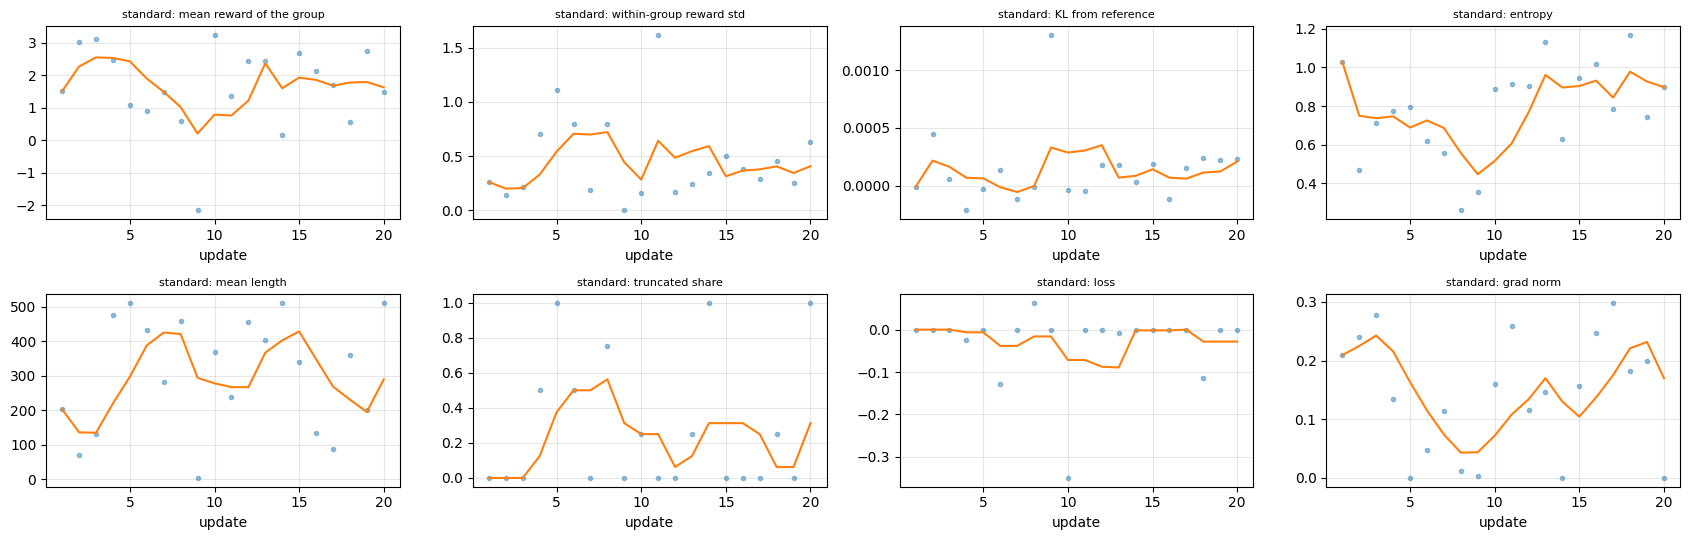

[PASS   ] standard: updates and verdict
            expected: 20 updates, STABLE
            actual  : 20, STABLE
[OBSERVE] compute for the report
            expected: peak VRAM and wall-clock of the standard continuation
            actual  : 8.00 GB, 6.7 min
[OBSERVE] uninformative-group fraction over the run
            expected: hypothesis: ~0 with a continuous reward model
            actual  : 0.05 (1/20 updates)
[OBSERVE] wasted compute: tokens in masked (max-length) completions
            expected: no right answer; this is sample inefficiency that the critic-free design does not fix
            actual  : 45.6% of 24728 generated tokens


In [8]:
# T8. Standard GRPO continuation: 20 updates from the GRPO midpoint, canonical normalisation.
if RUN_PARTS['C_standard'] and not has_adapter('standard'):
    run('python -m task3_grpo.continue_train --config configs/grpo.yaml --run-name standard --loss-type grpo')
elif has_adapter('standard'):
    print('standard: adapter already exists -> skipping training')
if has_adapter('standard'):
    v, s, LOG = report_grpo('standard')
    expect('standard: updates and verdict', f'{cfg["updates"]} updates, STABLE', f'{s["updates"]}, {v}', s['updates'] == cfg['updates'] and v == 'STABLE')
    expect('compute for the report', 'peak VRAM and wall-clock of the standard continuation', f'{s["peak_vram_gb"]:.2f} GB, {s["wall_clock_s"]/60:.1f} min', None)
    expect('uninformative-group fraction over the run', 'hypothesis: ~0 with a continuous reward model', f'{q(LOG, "uninformative_fraction"):.2f} ({sum(r["uninformative_fraction"] > 0 for r in LOG)}/{len(LOG)} updates)', None)
    expect('wasted compute: tokens in masked (max-length) completions', 'no right answer; this is sample inefficiency that the critic-free design does not fix',
           f'{s["wasted_token_fraction"]:.1%} of {s["generated_tokens"]} generated tokens', None)

In [9]:
# T9. Held-out evaluation: GRPO midpoint and standard, same protocol.
for name, adapter in [('midpoint', cfg['paths']['grpo_midpoint_policy']), ('standard', 'outputs/task3_grpo/standard')]:
    if has_eval(name): print(f'{name}: already evaluated')
    elif name == 'midpoint' or has_adapter('standard'):
        run(f'python -m task3_grpo.evaluate --config configs/grpo.yaml --adapter {adapter} --name {name} --n-prompts {N_EVAL}')
if has_eval('midpoint') and has_eval('standard'):
    M, S = eval_row('midpoint'), eval_row('standard')
    display(pd.DataFrame([M, S]).set_index('condition').round(4))
    d, ci, same, n = paired('midpoint', 'standard')
    expect('same protocol', f'{N_EVAL} prompts each', f'{M["n_prompts"]} / {S["n_prompts"]}', M['n_prompts'] == S['n_prompts'] == N_EVAL)
    expect('held-out reward: midpoint -> standard', 'hypothesis: higher; the paired difference must exceed its 95% interval to count',
           f'{M["reward"]:+.3f} -> {S["reward"]:+.3f}; paired diff {d:+.3f} +/- {ci:.3f}; identical answers {same}/{n}', None)
    expect('KL / entropy / length / truncation', 'hypothesis: KL up slightly; length depends on the normalisation (canonical may favour longer wrong answers)',
           f'KL {M["kl_token"]:.4f} -> {S["kl_token"]:.4f} | H {M["entropy"]:.3f} -> {S["entropy"]:.3f} | len {M["len_mean"]:.0f} -> {S["len_mean"]:.0f} | cut {M["trunc_rate"]:.0%} -> {S["trunc_rate"]:.0%}', None)

$ python -m task3_grpo.evaluate --config configs/grpo.yaml --adapter checkpoints/grpo_midpoint_policy --name midpoint --n-prompts 100
[midpoint] reward=+1.813 KL=0.0000 H=0.835 len=313 cut=11% distinct2=0.935
$ python -m task3_grpo.evaluate --config configs/grpo.yaml --adapter outputs/task3_grpo/standard --name standard --n-prompts 100
[standard] reward=+1.822 KL=0.0000 H=0.800 len=297 cut=6% distinct2=0.939


,reward,reward_std,kl_token,kl_seq,entropy,entropy_exact,len_mean,len_std,len_iqr,trunc_rate,distinct2,n_prompts
condition,,,,,,,,,,,,
midpoint,1.8133,1.2029,0.0,0.0091,0.8347,1.0519,312.68,264.1544,448.5,0.11,0.9351,100
standard,1.8221,1.1608,0.0,0.0148,0.8000,1.0095,296.82,260.3598,450.0,0.06,0.9391,100


[PASS   ] same protocol
            expected: 100 prompts each
            actual  : 100 / 100
[OBSERVE] held-out reward: midpoint -> standard
            expected: hypothesis: higher; the paired difference must exceed its 95% interval to count
            actual  : +1.813 -> +1.822; paired diff +0.009 +/- 0.193; identical answers 14/100
[OBSERVE] KL / entropy / length / truncation
            expected: hypothesis: KL up slightly; length depends on the normalisation (canonical may favour longer wrong answers)
            actual  : KL 0.0000 -> 0.0000 | H 0.835 -> 0.800 | len 313 -> 297 | cut 11% -> 6%


## Part D - group-size study (supplied cache, no training)

**Write down first:** which difficulty bin gains most from larger groups - hard, medium or easy?

$ python -m task3_grpo.analyze_group_size --config configs/grpo.yaml
Cached prompts: 24 | completions per prompt used: 8 | reward field: reward
Cache row keys: ['clipped_at_max', 'completion', 'completion_tokens', 'generation_index', 'prompt_id', 'reward', 'source_index', 'terminated_with_eos']
Group sizes to analyze: [2, 4, 8]
  K=2: 96 groups | informative 0.938 | mean std 0.385 | var(r-mu) 0.337 | +-1 advantages 0.94 | sign agreement 0.745
  K=4: 48 groups | informative 0.958 | mean std 0.541 | var(r-mu) 0.468 | +-1 advantages 0.00 | sign agreement 0.886
  K=8: 24 groups | informative 0.958 | mean std 0.619 | var(r-mu) 0.560 | +-1 advantages 0.00 | sign agreement 1.000
saved -> /tmp/PA2/results/task3_grpo/group_size_study.json
Budget: 24 prompts x 8 completions = 192 completions in every condition. Difficulty bins: terciles of each prompt's 8-completion mean reward -> cutoffs [1.313 2.421], sizes {'hard': 8, 'medium': 8, 'easy': 8}


,n_groups,informative_rate,small_spread_rate_lt0.1,mean_group_std,var_centered,var_adv,mean_abs_adv,frac_adv_pm1,sign_agreement,baseline_mse,frac_completions_with_signal_after_masking
K,,,,,,,,,,,
2,96.0,0.9375,0.2396,0.3846,0.3368,0.9375,0.9375,0.9375,0.7446,0.2231,0.7865
4,48.0,0.9583,0.0625,0.5410,0.4677,0.9583,0.8307,0.0000,0.8859,0.0922,0.8073
8,24.0,0.9583,0.0417,0.6191,0.5599,0.9583,0.7939,0.0000,1.0000,0.0000,0.8073


,informative_rate,mean_group_std,var_centered,sign_agreement,baseline_mse
2_hard,0.8438,0.4934,0.5984,0.6964,0.2885
2_medium,0.9688,0.4124,0.3041,0.7812,0.1428
2_easy,1.0000,0.2479,0.1080,0.7500,0.2379
4_hard,0.8750,0.6615,0.7865,0.8393,0.1004
4_medium,1.0000,0.5517,0.4017,0.9062,0.0452
4_easy,1.0000,0.4098,0.2149,0.9062,0.1309
8_hard,0.8750,0.7634,0.8869,1.0000,0.0000
8_medium,1.0000,0.5990,0.4469,1.0000,0.0000
8_easy,1.0000,0.4948,0.3459,1.0000,0.0000


[PASS   ] K = 2: every informative group gives advantages of exactly +-1
            expected: frac(|A| = 1) == informative rate (a mathematical identity for two distinct rewards)
            actual  : 0.938 vs 0.938
[OBSERVE] informative-group rate vs K
            expected: hypothesis: ~1 for every K with a continuous reward (more siblings -> fewer accidental ties)
            actual  : {'2': np.float64(0.9375), '4': np.float64(0.9583), '8': np.float64(0.9583)}
[OBSERVE] within-group std vs K
            expected: hypothesis: rises with K (small groups underestimate the spread: E[s^2] = (K-1)/K sigma^2)
            actual  : {'2': np.float64(0.3846), '4': np.float64(0.541), '8': np.float64(0.6191)}
[OBSERVE] sign agreement with the full 8-answer verdict
            expected: hypothesis: rises with K (1 at K = 8 by definition): small groups often call a worse-than-average answer "better"
            actual  : {'2': np.float64(0.7446), '4': np.float64(0.8859), '8': np.float64(1.0)}
[OB

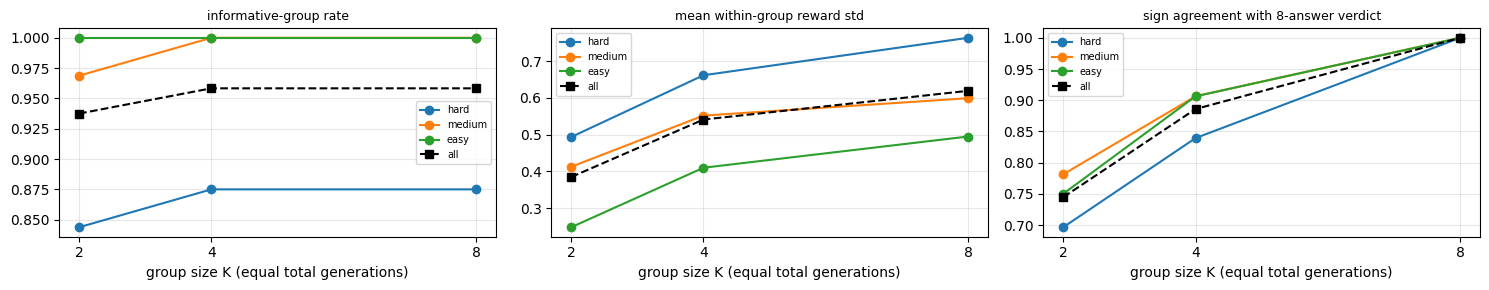

In [10]:
# T10. Group-size study on the supplied cache: K in {2, 4, 8} at an EQUAL generation budget (CPU, seconds).
if RUN_PARTS['D_group']:
    run('python -m task3_grpo.analyze_group_size --config configs/grpo.yaml')
G = load_json(f'{RES}/group_size_study.json')
print(f'Budget: {G["n_prompts"]} prompts x 8 completions = {G["total_completions"]} completions in every condition. Difficulty bins: {G["difficulty_rule"]} -> cutoffs {np.round(G["difficulty_cutoffs"], 3)}, sizes {G["bin_sizes"]}')
cols = ['n_groups', 'informative_rate', 'small_spread_rate_lt0.1', 'mean_group_std', 'var_centered', 'var_adv', 'mean_abs_adv', 'frac_adv_pm1', 'sign_agreement', 'baseline_mse', 'frac_completions_with_signal_after_masking']
PK = pd.DataFrame(G['per_k']).T[cols].astype(float); PK.index.name = 'K'; display(PK.round(4))
PB = pd.DataFrame(G['per_k_bin']).T[['informative_rate', 'mean_group_std', 'var_centered', 'sign_agreement', 'baseline_mse']].astype(float); display(PB.round(4))
expect('K = 2: every informative group gives advantages of exactly +-1', 'frac(|A| = 1) == informative rate (a mathematical identity for two distinct rewards)',
       f'{PK.loc["2", "frac_adv_pm1"]:.3f} vs {PK.loc["2", "informative_rate"]:.3f}', abs(PK.loc['2', 'frac_adv_pm1'] - PK.loc['2', 'informative_rate']) < 1e-6)
expect('informative-group rate vs K', 'hypothesis: ~1 for every K with a continuous reward (more siblings -> fewer accidental ties)', dict(PK['informative_rate'].round(4)), None)
expect('within-group std vs K', 'hypothesis: rises with K (small groups underestimate the spread: E[s^2] = (K-1)/K sigma^2)', dict(PK['mean_group_std'].round(4)), None)
expect('sign agreement with the full 8-answer verdict', 'hypothesis: rises with K (1 at K = 8 by definition): small groups often call a worse-than-average answer "better"',
       dict(PK['sign_agreement'].round(4)), None)
expect('which difficulty bins benefit most from larger K (RQ1)', 'compare the K = 2 -> 8 gain in sign agreement / spread across hard, medium, easy',
       {b: f'agree {PB.loc[f"2_{b}", "sign_agreement"]:.3f} -> {PB.loc[f"8_{b}", "sign_agreement"]:.3f}, std {PB.loc[f"2_{b}", "mean_group_std"]:.3f} -> {PB.loc[f"8_{b}", "mean_group_std"]:.3f}' for b in ['hard', 'medium', 'easy']}, None)
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, (key, t_) in zip(axes, [('informative_rate', 'informative-group rate'), ('mean_group_std', 'mean within-group reward std'), ('sign_agreement', 'sign agreement with 8-answer verdict')]):
    for b in ['hard', 'medium', 'easy']:
        ax.plot([2, 4, 8], [PB.loc[f'{k}_{b}', key] for k in [2, 4, 8]], marker='o', label=b)
    ax.plot([2, 4, 8], [PK.loc[str(k), key] for k in [2, 4, 8]], 'k--', marker='s', label='all')
    ax.set_xticks([2, 4, 8]); ax.set_xlabel('group size K (equal total generations)'); ax.set_title(t_, fontsize=9); ax.legend(fontsize=7); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(f'{FIG}/group_size.png', dpi=140); plt.show(); plt.close(fig)

## Part E - canonical vs Dr.-GRPO normalisation

**Write down first:** will Dr. GRPO answers be longer or shorter after 8 updates?

$ python -m task3_grpo.compare_normalization --config configs/grpo.yaml --skip-existing --n-prompts 100
Fork updates: 8 | loss types: ['grpo', 'dr_grpo']
[fork_grpo] GRPO (grpo) continuation: 8 updates x 1 prompt x K=4 | eps=0.2 beta=0.1 lr=5e-06 | from checkpoints/grpo_midpoint_policy
[fork_grpo] update  1/8 reward=+1.511 groupSD=0.262 KL=-0.0000 H=1.027 len=202 cut=0.00 gnorm=0.209 |rho-1|=0.0e+00 helperdiff=2.5e-08
[fork_grpo] update  2/8 reward=+3.018 groupSD=0.141 KL=0.0004 H=0.472 len=70 cut=0.00 gnorm=0.241 |rho-1|=0.0e+00 helperdiff=1.6e-08
[fork_grpo] update  3/8 reward=+3.104 groupSD=0.214 KL=0.0001 H=0.712 len=132 cut=0.00 gnorm=0.278 |rho-1|=0.0e+00 helperdiff=1.7e-08
[fork_grpo] update  4/8 reward=+2.473 groupSD=0.704 KL=-0.0002 H=0.776 len=475 cut=0.50 gnorm=0.135 |rho-1|=0.0e+00 helperdiff=3.7e-09
[fork_grpo] update  5/8 reward=+1.092 groupSD=1.109 KL=-0.0000 H=0.796 len=512 cut=1.00 gnorm=0.000 |rho-1|=0.0e+00 helperdiff=0.0e+00
[fork_grpo] update  6/8 reward=+0.910 gro

,loss_type,updates,generated_tokens,wasted_token_fraction,heldout_reward,heldout_kl,heldout_entropy,heldout_len,heldout_len_std,heldout_trunc,heldout_distinct2
condition,,,,,,,,,,,
fork_grpo,grpo,8,10254,0.5492,1.6788,0.0,0.8257,297.47,261.9753,0.10,0.9418
fork_dr_grpo,dr_grpo,8,10073,0.5083,1.7412,0.0,0.8277,290.36,251.5175,0.08,0.9308


[PASS   ] forks are matched
            expected: same updates and prompt schedule; identical completions at update 1 (same start, same seed)
            actual  : updates [8, 8], schedules identical True, update-1 identical samples True
[PASS   ] update 1, same completions: grad-norm ratio Dr / canonical
            expected: equals length / 512 (the only difference is dividing by 512 instead of T)  -> correlation ~ 1
            actual  : corr(ratio, length/512) = +1.0000; e.g. T=166: 0.324 vs 0.324, T=301: 0.588 vs 0.588, T=155: 0.303 vs 0.303, T=188: 0.367 vs 0.367
[OBSERVE] grpo: length-conditioned gradient
            expected: hypothesis: canonical ~flat in length (each answer weighted |A|); Dr. GRPO grows with length (|A| T / 512)
            actual  : corr(length, grad norm) -0.345; long/short grad norm 0.44 (wrong answers 0.42, right answers 0.46); n = 21
[OBSERVE] dr_grpo: length-conditioned gradient
            expected: hypothesis: canonical ~flat in length (each answer we

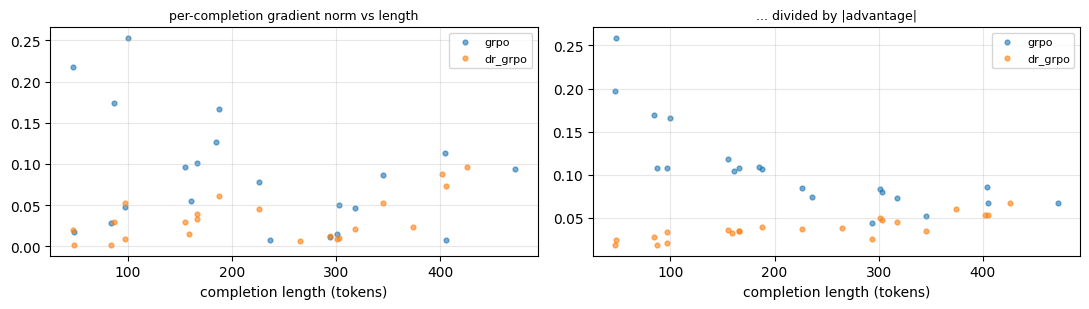

In [11]:
# T11. Canonical GRPO vs Dr.-GRPO normalisation: matched 8-update forks + the length-conditioned gradient test.
if RUN_PARTS['E_norm']:
    run(f'python -m task3_grpo.compare_normalization --config configs/grpo.yaml --skip-existing --n-prompts {N_EVAL}')
if os.path.exists(f'{RES}/normalization_study.json'):
    NS = load_json(f'{RES}/normalization_study.json'); LC = NS['length_conditioned']
    for n in ['fork_grpo', 'fork_dr_grpo']: report_grpo(n, plot=False)
    F_ = pd.DataFrame(NS['forks']).set_index('condition'); display(F_.round(4))
    sch = [[tuple(r['prompt_indices']) for r in read_jsonl(f'{RES}/{n}/train_log.jsonl')] for n in ['fork_grpo', 'fork_dr_grpo']]
    expect('forks are matched', 'same updates and prompt schedule; identical completions at update 1 (same start, same seed)',
           f'updates {list(F_["updates"])}, schedules identical {sch[0] == sch[1]}, update-1 identical samples {LC["update1_paired"]["identical_samples"]}',
           len(set(F_['updates'])) == 1 and sch[0] == sch[1] and LC['update1_paired']['identical_samples'])
    pr = LC['update1_paired']['length_and_ratio_dr_over_grpo']
    if pr:
        Ls, Rs = np.array([p[0] for p in pr], float), np.array([p[1] for p in pr], float)
        expect('update 1, same completions: grad-norm ratio Dr / canonical', 'equals length / 512 (the only difference is dividing by 512 instead of T)  -> correlation ~ 1',
               f'corr(ratio, length/512) = {np.corrcoef(Rs, Ls / 512)[0, 1]:+.4f}; e.g. ' + ', '.join(f'T={int(l)}: {r:.3f} vs {l/512:.3f}' for l, r in list(zip(Ls, Rs))[:4]),
               len(pr) > 2 and np.corrcoef(Rs, Ls / 512)[0, 1] > 0.99)
    for lt in ['grpo', 'dr_grpo']:
        d = LC[lt]
        expect(f'{lt}: length-conditioned gradient', 'hypothesis: canonical ~flat in length (each answer weighted |A|); Dr. GRPO grows with length (|A| T / 512)',
               f'corr(length, grad norm) {d["corr_len_gradnorm"]:+.3f}; long/short grad norm {d["long_over_short"]:.2f} (wrong answers {d["long_over_short_negative_adv"]:.2f}, right answers {d["long_over_short_positive_adv"]:.2f}); n = {d["n_completions"]}', None)
    a, b = F_.loc['fork_grpo'], F_.loc['fork_dr_grpo']
    dd, ci, same, n = paired('fork_grpo', 'fork_dr_grpo')
    expect('held-out behaviour: canonical -> Dr. GRPO', 'hypothesis (Liu et al.): Dr. GRPO is not biased towards longer wrong answers; at 8 updates expect small effects',
           f'reward {a.heldout_reward:+.3f} -> {b.heldout_reward:+.3f} (paired {dd:+.3f} +/- {ci:.3f}) | len {a.heldout_len:.0f} -> {b.heldout_len:.0f} | KL {a.heldout_kl:.4f} -> {b.heldout_kl:.4f} | cut {a.heldout_trunc:.0%} -> {b.heldout_trunc:.0%}', None)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    for lt, name in [('grpo', 'fork_grpo'), ('dr_grpo', 'fork_dr_grpo')]:
        cs = [c for r in read_jsonl(f'{RES}/{name}/train_log.jsonl') for c in r['per_completion'] if not c['masked'] and c['grad_norm'] > 0]
        ax[0].scatter([c['length'] for c in cs], [c['grad_norm'] for c in cs], s=12, alpha=.6, label=lt)
        ax[1].scatter([c['length'] for c in cs], [c['grad_norm'] / max(abs(c['adv']), 1e-6) for c in cs], s=12, alpha=.6, label=lt)
    ax[0].set_title('per-completion gradient norm vs length', fontsize=9); ax[1].set_title('... divided by |advantage|', fontsize=9)
    for a_ in ax: a_.set_xlabel('completion length (tokens)'); a_.legend(fontsize=8); a_.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(f'{FIG}/normalization_gradients.png', dpi=140); plt.show(); plt.close(fig)

## Part F - qualitative candidates

In [12]:
# T12. Qualitative candidates. The notebook FINDS them; whether an answer is better is your judgement.
# (i) group informativeness: the cached prompt whose 8 answers are closest in reward -- what K = 2 does with it
from task3_grpo.analyze_group_size import load_k8_cache, reward_key
C8 = load_k8_cache(cfg['group_cache']); rk = reward_key(next(iter(C8.values()))[0])
tight = min(C8, key=lambda p: np.std([x[rk] for x in C8[p][:8]]))
rs = [x[rk] for x in C8[tight][:8]]
print(f'(i) Tightest cached group (prompt {tight}): 8 rewards {np.round(rs, 3)} (std {np.std(rs):.3f})')
print('    K = 2 groups ->', [np.round((np.array(rs[j:j+2]) - np.mean(rs[j:j+2])) / (np.std(rs[j:j+2]) + 1e-6), 2).tolist() for j in range(0, 8, 2)])
print('    a reward gap this small can be reward-model noise, yet K = 2 turns it into a full +1 / -1 push.')
txt = next((x.get('response') or x.get('completion') or x.get('text')) for x in C8[tight][:1])
if txt: print('    answer 0:', clip(txt, 250))
# (ii) normalisation: the longest and shortest negative-advantage completions in the forks' first update (identical samples)
roll = read_jsonl(f'{RES}/fork_grpo/rollouts.jsonl') if os.path.exists(f'{RES}/fork_grpo/rollouts.jsonl') else []
u1 = [r for r in roll if r['update'] == 1]
neg = sorted([r for r in u1 if r['advantage'] < 0 and not r['truncated']], key=lambda r: r['length'])
if len(neg) >= 2:
    s_, l_ = neg[0], neg[-1]
    print(f'\n(ii) Update 1, two answers judged WORSE than their siblings (same prompt):')
    for tag, r in [('short', s_), ('long', l_)]:
        print(f'   [{tag}] {r["length"]} tokens, A = {r["advantage"]:+.2f} -> per-token push: canonical {abs(r["advantage"]) / r["length"]:.4f}, Dr. {abs(r["advantage"]) / 512:.4f}')
        print('     ', clip(r['response'], 220))
# (iii) held-out: largest length change between canonical and Dr. forks on the same prompt
if has_eval('fork_grpo') and has_eval('fork_dr_grpo'):
    A_, B_ = [{r['index']: r for r in read_jsonl(f'{RES}/{n}/eval_generations.jsonl')} for n in ('fork_grpo', 'fork_dr_grpo')]
    i = max(A_, key=lambda i: abs(B_[i]['length_tokens'] - A_[i]['length_tokens']))
    print(f'\n(iii) Held-out prompt #{i}: canonical {A_[i]["length_tokens"]} tok (R {A_[i]["reward"]:+.2f}) vs Dr. {B_[i]["length_tokens"]} tok (R {B_[i]["reward"]:+.2f})')
    print('   PROMPT   :', clip(A_[i]['prompt'], 180)); print('   canonical:', clip(A_[i]['response'])); print('   Dr. GRPO :', clip(B_[i]['response']))
    print('   (single prompts differ mostly by sampling when policies are close -- use as illustration, not proof)')

(i) Tightest cached group (prompt 280): 8 rewards [1.273 1.273 1.273 1.273 1.273 1.273 1.273 1.273] (std 0.000)
    K = 2 groups -> [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
    a reward gap this small can be reward-model noise, yet K = 2 turns it into a full +1 / -1 push.
    answer 0: 0

(ii) Update 1, two answers judged WORSE than their siblings (same prompt):
   [short] 155 tokens, A = -0.81 -> per-token push: canonical 0.0052, Dr. 0.0016
      Newborn gorillas cannot get pregnant because they do not have reproductive organs that allow them to produce offspring through sexual intercourse or other means. Gorillas and other mammals reproduce sexually, with males  ...
   [long] 166 tokens, A = -0.93 -> per-token push: canonical 0.0056, Dr. 0.0018
      It's important to note that newborn gorillas cannot get pregnant because they are still developing and not yet sexually mature. Gorillas typically do not reach sexual maturity until around 3-4 years of age for males and  ...

(ii

## Part G - RQ3 evidence

In [13]:
# T13. RQ3 evidence: with the critic gone, what limits GRPO here? (CPU, from the saved standard log)
L_ = read_jsonl(f'{RES}/standard/train_log.jsonl'); s_ = load_json(f'{RES}/standard/train_summary.json')
gstd = np.array([r['group_reward_std'] for r in L_]); gn = np.array([r['grad_norm'] for r in L_], float)
rows = {'uninformative groups (std < 1e-6)': f'{np.mean(gstd < 1e-6):.0%} of updates',
        'near-uninformative groups (std < 0.1)': f'{np.mean(gstd < 0.1):.0%} of updates  (0.1 ~ the reward model\'s own scoring noise seen in Tasks 1-2)',
        'wasted tokens (masked max-length completions)': f'{s_["wasted_token_fraction"]:.1%}',
        'updates with >= 1 masked completion': f'{np.mean([r["truncated_fraction"] > 0 for r in L_]):.0%}',
        'grad-norm variability (coefficient of variation)': f'{np.nanstd(gn) / np.nanmean(gn):.2f}',
        'baseline from only K = 4 samples': 'see T10: sign agreement with the 8-answer verdict at K = 4',
        'clip activity': f'max |rho - 1| {max(r["max_abs_ratio_minus_1"] for r in L_):.1e} -> never binds with policy_epochs = 1'}
for k_, v_ in rows.items(): print(f'  {k_:48s} {v_}')
expect('RQ3: dominant source of instability / sample inefficiency', 'compare the rows above: the group-relative signal itself (spread vs scoring noise, small K) or wasted max-length samples', 'read the table', None)
json.dump({k_: v_ for k_, v_ in rows.items()}, open(f'{RES}/rq3_evidence.json', 'w'), indent=2)

  uninformative groups (std < 1e-6)                5% of updates
  near-uninformative groups (std < 0.1)            5% of updates  (0.1 ~ the reward model's own scoring noise seen in Tasks 1-2)
  wasted tokens (masked max-length completions)    45.6%
  updates with >= 1 masked completion              45%
  grad-norm variability (coefficient of variation) 0.70
  baseline from only K = 4 samples                 see T10: sign agreement with the 8-answer verdict at K = 4
  clip activity                                    max |rho - 1| 0.0e+00 -> never binds with policy_epochs = 1
[OBSERVE] RQ3: dominant source of instability / sample inefficiency
            expected: compare the rows above: the group-relative signal itself (spread vs scoring noise, small K) or wasted max-length samples
            actual  : read the table


## Part S - save

In [14]:
# T14. Save everything. Run this even if a cell above failed.
names = ['midpoint', 'standard', 'fork_grpo', 'fork_dr_grpo']
rows = [eval_row(n) for n in names if has_eval(n)]
if rows:
    summary = pd.DataFrame(rows).set_index('condition'); summary.to_csv(f'{RES}/task3_summary.csv')
    print('TASK 3 SUMMARY:'); display(summary.round(4))
def zip_dir(src, arc_root, dst, skip=('smoke',)):
    with zipfile.ZipFile(dst, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in Path(src).rglob('*'):
            rel = p.relative_to(src)
            if p.is_file() and not any(s in str(rel) for s in skip):
                z.write(p, f'{arc_root}/{rel}')
zip_dir(f'{OUT}/results/task3_grpo', 'results/task3_grpo', f'{OUT}/task3_results.zip')
zip_dir(f'{OUT}/outputs/task3_grpo', 'outputs/task3_grpo', f'{OUT}/task3_adapters.zip')
for f in sorted(os.listdir(OUT)):
    if os.path.isfile(f'{OUT}/{f}'): print(f'{os.path.getsize(f"{OUT}/{f}") / 1e6:8.2f} MB  {f}')
tally = Counter(t for t, _ in CHECKS)
print(f'\nChecks: {tally.get("PASS", 0)} PASS | {tally.get("FAIL", 0)} FAIL | {tally.get("OBSERVE", 0)} OBSERVE')
for t, n in CHECKS:
    if t == 'FAIL': print('   FAIL:', n)
print('\ntask3_results.zip  -> unzip at your repo root and COMMIT')
print('task3_adapters.zip -> do NOT commit; Task 4 needs outputs/task3_grpo/standard')

TASK 3 SUMMARY:


,reward,reward_std,kl_token,kl_seq,entropy,entropy_exact,len_mean,len_std,len_iqr,trunc_rate,distinct2,n_prompts
condition,,,,,,,,,,,,
midpoint,1.8133,1.2029,0.0,0.0091,0.8347,1.0519,312.68,264.1544,448.50,0.11,0.9351,100
standard,1.8221,1.1608,0.0,0.0148,0.8000,1.0095,296.82,260.3598,450.00,0.06,0.9391,100
fork_grpo,1.6788,1.1797,0.0,0.0072,0.8257,1.0369,297.47,261.9753,447.25,0.10,0.9418,100
fork_dr_grpo,1.7412,1.0889,0.0,0.0097,0.8277,1.0326,290.36,251.5175,405.50,0.08,0.9308,100


   12.13 MB  task3_adapters.zip
    0.74 MB  task3_results.zip

Checks: 29 PASS | 0 FAIL | 15 OBSERVE

task3_results.zip  -> unzip at your repo root and COMMIT
task3_adapters.zip -> do NOT commit; Task 4 needs outputs/task3_grpo/standard


## Notes
- **A FAIL in T5-T7 means a pipeline bug**: stop and send the output to Claude before training.
- **Task 4 uses `outputs/task3_grpo/standard` exactly.**
- **Decisions to state in the report:** per-group population std with denominator (std + 1e-6) as in
  the manual; truncated completions masked from the loss but kept in the group statistics (TRL
  convention); one optimisation pass (release config), so the clip never binds; each completion
  back-propagated separately to measure its own gradient norm (losses verified to sum to the helper);
  dropout off; fp16 autocast + GradScaler with fp32 LoRA weights; held-out cap 768 tokens (same as
  Task 2); group-size budget = each prompt's first 8 cached completions split into 8/K disjoint
  groups; difficulty = terciles of the 8-answer mean reward; Dr.-GRPO-style = constant 512 divisor
  only (the advantage keeps its std scaling, so only the normalisation differs).
- **The pipeline is the scripts** (`python -m task3_grpo.*`); this notebook only runs and checks them.